In [1]:
import pandas as pd
import numpy as np
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import LeaveOneGroupOut
from tqdm import tqdm
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score

tqdm.pandas()

In [2]:
cleanDf = pd.read_csv(f'../data/processed/cicids2017_clean.csv')
cleanDf.head(5)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file,is_attack
0,49188,4,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,Monday,0
1,49188,1,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,Monday,0
2,49486,3,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,Monday,0
3,49486,1,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,Monday,0
4,88,609,7,4,484,414,233,0,69.142857,111.967895,...,0.0,0,0,0.0,0.0,0,0,BENIGN,Monday,0


In [3]:
cleanDf['source_file'].unique()

<ArrowStringArray>
[                         'Monday',                         'Tuesday',
                       'Wednesday',     'Thursday-Morning-WebAttacks',
 'Thursday-Afternoon-Infiltration',                  'Friday-Morning',
       'Friday-Afternoon-PortScan',           'Friday-Afternoon-DDoS']
Length: 8, dtype: str

In [4]:
X = cleanDf.drop(columns=['Label','source_file','is_attack'])
y = cleanDf[['is_attack']]
groups = cleanDf['source_file'].str.split('-').str[0]

one_day_out_spliter = LeaveOneGroupOut()
n_folds = one_day_out_spliter.get_n_splits(groups=groups)

# So first we are going to test out predicting the majority class ON THE TRAINING DAY! ALSO, Very important to give these naive methods the change of working we are also going to just predict attack versus non-attack.

In [5]:
conf_matrixes = []
acc_scores = []
day_left_out = []

for train_idx, test_idx in tqdm(one_day_out_spliter.split(X,y,groups), total = n_folds ):
    
    maj_classifier = DummyClassifier(strategy='most_frequent')

    # Now we'll "train" on or really just get the most frequent class for the previous day.
    X_train_curr = X.iloc[train_idx]
    y_train_curr = y.iloc[train_idx]

    X_test_curr = X.iloc[test_idx]
    y_test_curr = y.iloc[test_idx]

    day_left_out.append(groups[test_idx[0]])

    maj_classifier.fit(X_train_curr, y_train_curr, sample_weight=None)

    preds = maj_classifier.predict(X_test_curr)
    
    

    conf_mat = confusion_matrix(y_test_curr, preds, labels=[1,0], normalize='true')

    if(y_test_curr[y_test_curr['is_attack'] == 1].shape[0] == 0):
        conf_mat[0,:] = np.nan
    
    conf_matrixes.append(conf_mat)
    acc_scores.append(accuracy_score(y_test_curr, preds, normalize=True))



conf_matrixes = np.array(conf_matrixes)


100%|██████████| 5/5 [00:03<00:00,  1.50it/s]


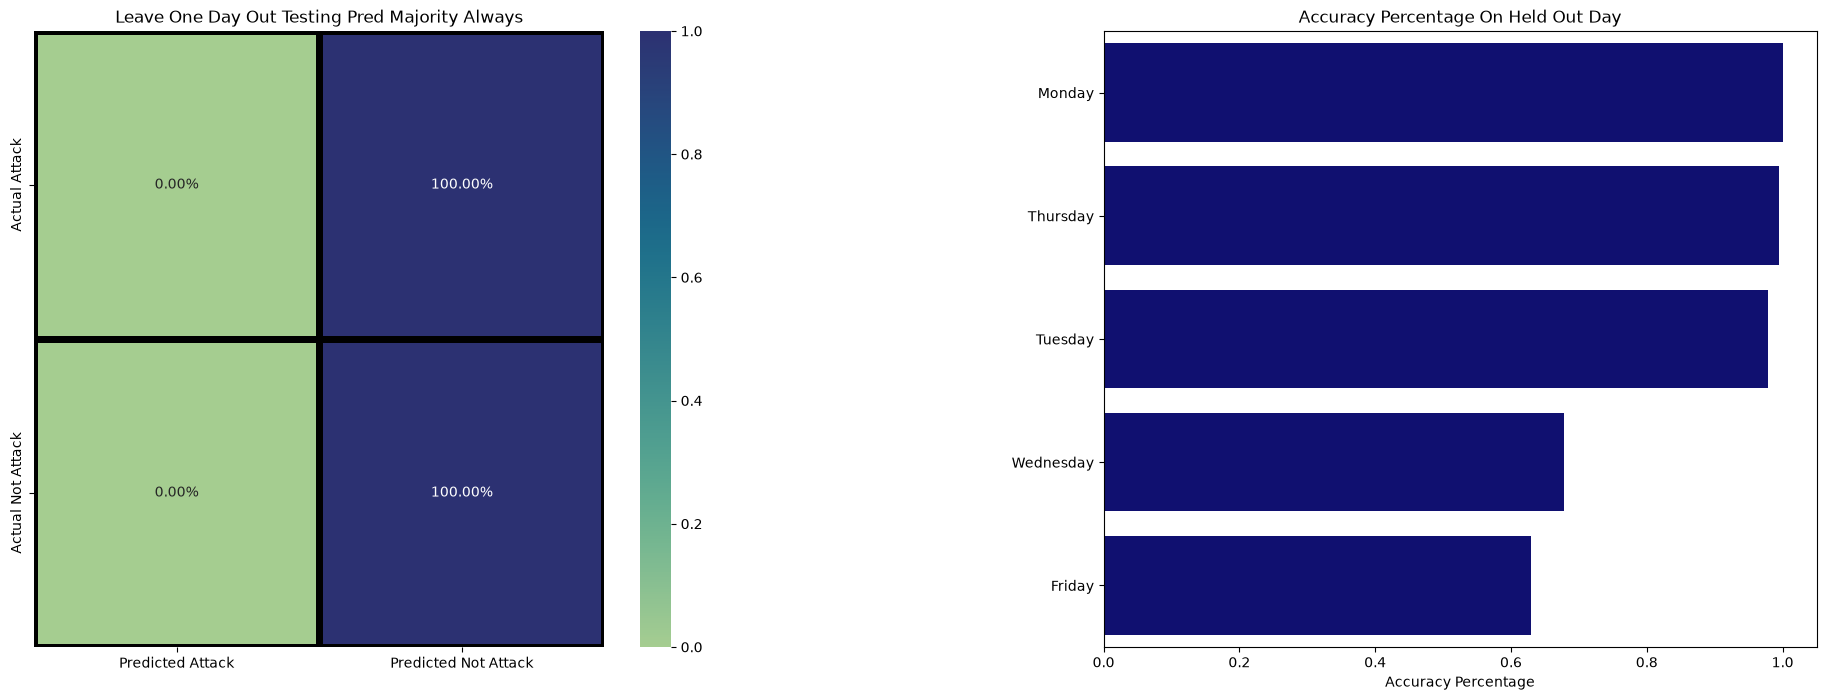

In [6]:
acc_info_alwayssame = pd.DataFrame()
acc_info_alwayssame['day_out'] = day_left_out
acc_info_alwayssame['acc_scores'] = acc_scores
acc_info_alwayssame  = acc_info_alwayssame.sort_values(by="acc_scores",ascending=False)

fig, (ax1, ax2) = plt.subplots(1,2,figsize=(23, 8))
plt.subplots_adjust(wspace=0.5, hspace=0.0)


confusion_avg_alwayssame = pd.DataFrame(np.nanmean(conf_matrixes,axis=0),index=["Actual Attack","Actual Not Attack"], columns= ["Predicted Attack","Predicted Not Attack"] )
sns.heatmap(data=confusion_avg_alwayssame,linewidths=5,linecolor="black",cmap="crest",annot=True,fmt=".2%",ax=ax1)
ax1.set_title("Leave One Day Out Testing Pred Majority Always")


sns.barplot(data=acc_info_alwayssame,y='day_out',x='acc_scores',ax=ax2,color="navy")
ax2.set_title("Accuracy Percentage On Held Out Day")
ax2.set_xlabel("Accuracy Percentage")
ax2.set_ylabel("")

plt.show()

# TODO EXPLANATION HERE!

# Now we'll do another niave baseline where we add some randomness to the predictions, but the predictions are still biased towards the majority class. 

In [7]:
conf_matrixes_strat = []
acc_scores_strat = []
day_left_out_strat = []

for train_idx, test_idx in tqdm(one_day_out_spliter.split(X,y,groups), total = n_folds ):
    
    strat_classifier = DummyClassifier(strategy='stratified',random_state=5502)

    # Now we'll "train" on or really just get the most frequent class for the previous day.
    X_train_curr = X.iloc[train_idx]
    y_train_curr = y.iloc[train_idx]

    X_test_curr = X.iloc[test_idx]
    y_test_curr = y.iloc[test_idx]

    day_left_out_strat.append(groups[test_idx[0]])

    strat_classifier.fit(X_train_curr, y_train_curr, sample_weight=None)

    preds = strat_classifier.predict(X_test_curr)

    

    conf_mat = confusion_matrix(y_test_curr, preds, labels=[1,0], normalize='true')

    if(y_test_curr[y_test_curr['is_attack'] == 1].shape[0] == 0):
        conf_mat[0,:] = np.nan
    
    conf_matrixes_strat.append(conf_mat)
    acc_scores_strat.append(accuracy_score(y_test_curr, preds, normalize=True))

conf_matrixes_strat = np.array(conf_matrixes_strat)

100%|██████████| 5/5 [00:03<00:00,  1.44it/s]


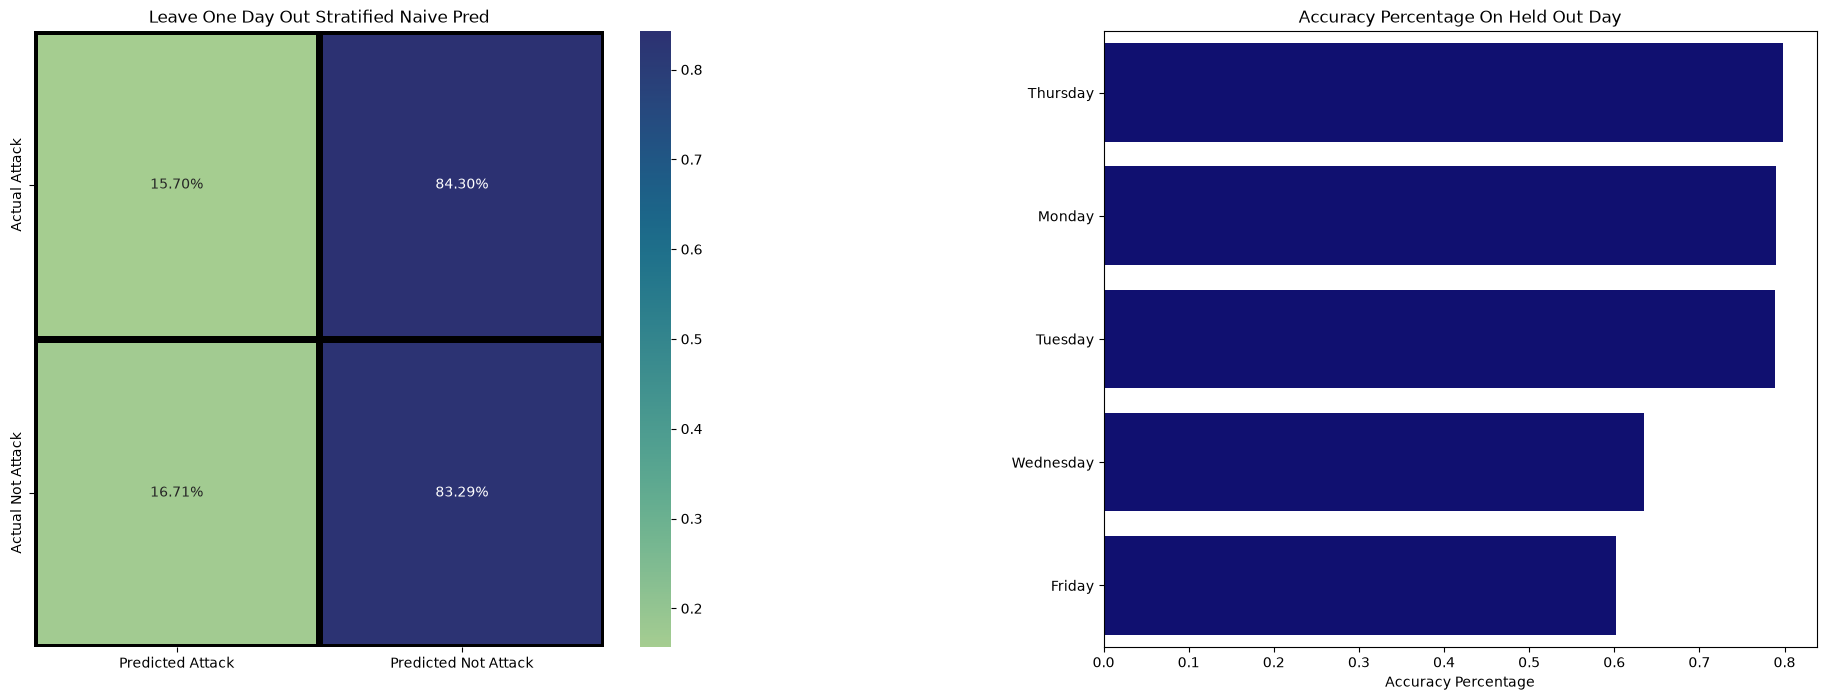

In [8]:
acc_info_strat = pd.DataFrame()
acc_info_strat['day_out'] = day_left_out_strat
acc_info_strat['acc_scores'] = acc_scores_strat
acc_info_strat  = acc_info_strat.sort_values(by="acc_scores",ascending=False)

fig, (ax1, ax2) = plt.subplots(1,2,figsize=(23, 8))
plt.subplots_adjust(wspace=0.5, hspace=0.0)


confusion_avg_strat = pd.DataFrame(np.nanmean(conf_matrixes_strat,axis=0),index=["Actual Attack","Actual Not Attack"], columns= ["Predicted Attack","Predicted Not Attack"] )
sns.heatmap(data=confusion_avg_strat,linewidths=5,linecolor="black",cmap="crest",annot=True,fmt=".2%",ax=ax1)
ax1.set_title("Leave One Day Out Stratified Naive Pred")


sns.barplot(data=acc_info_strat,y='day_out',x='acc_scores',ax=ax2,color="navy")
ax2.set_title("Accuracy Percentage On Held Out Day")
ax2.set_xlabel("Accuracy Percentage")
ax2.set_ylabel("")

plt.show()

# TODO ADD EXPLANATION HERE!